# Module 04 — AlexNet (depth · ReLU · dropout · augmentation, at scale)

Module 03's convolution reads digits. This module is about what it took to make
the same machinery read *photographs*: a network big enough to matter — and the
handful of tricks that kept it from simply memorizing its training set. In
2012 Krizhevsky, Sutskever & Hinton put them together, trained the result on
two gaming GPUs for a week, and won ImageNet by ten points.

Everything new joins `nanograd` in both languages: **stride and padding** for
convolutions, **overlapping max-pooling**, **dropout** (with `train()`/`eval()`
modes), AlexNet's **local response normalization**, and **crop + flip
augmentation**. We build each from its definition, check it numerically, show
the regularizers working on a tiny toy, then train a scaled-down AlexNet on
CIFAR-10 — and close by cross-checking against PyTorch, TensorFlow and Keras.

In [1]:
import os, sys, math, time
# Windows + conda: conda's MKL (via LLVM OpenMP) and pip's PyTorch each bring
# an OpenMP runtime, and two in one process crash whichever loads first.
# Running MKL single-threaded keeps it from loading one at all; the heavy
# CIFAR training here is cached, so the cost is small. (A no-op wherever
# NumPy uses OpenBLAS instead of MKL.)
os.environ.setdefault('MKL_THREADING_LAYER', 'SEQUENTIAL')
import numpy as np
import matplotlib.pyplot as plt

# Locate the repo root whether Jupyter was launched from it or the module folder.
def _find_repo():
    here = os.getcwd()
    cands = [here] + [os.path.abspath(os.path.join(here, *(['..'] * k))) for k in range(1, 6)]
    for base in cands:
        if os.path.isdir(os.path.join(base, 'lib', 'python', 'nanograd')):
            return base
    return here

REPO = _find_repo()
TOPIC = os.path.join(REPO, 'topics', '04-alexnet')
sys.path.insert(0, os.path.join(REPO, 'lib', 'python'))   # nanograd
sys.path.insert(0, os.path.join(TOPIC, 'python'))          # canonical alexnet.py
sys.path.insert(0, os.path.join(TOPIC, 'tests'))           # check_utils
sys.path.insert(0, os.path.join(REPO, 'data'))             # get_cifar10

import nanograd as ng
import alexnet as canon
from check_utils import rel_error, eval_numerical_gradient, eval_numerical_gradient_array
np.set_printoptions(precision=4, suppress=True)
print('new in nanograd:', ['Dropout', 'LocalResponseNorm', 'random_crop_flip', 'ten_crop',
                           'conv_out_size'], '+ Conv2D(stride, pad), MaxPool2D(P, stride)')

new in nanograd: ['Dropout', 'LocalResponseNorm', 'random_crop_flip', 'ten_crop', 'conv_out_size'] + Conv2D(stride, pad), MaxPool2D(P, stride)


## 1. The toy: mirror glyphs

Each 12×12 RGB image holds one 5×5 corner glyph — a vertical stroke joined to a
horizontal stroke at the **bottom** (class 0) or the **top** (class 1) — in a
random color, at a random spot, over faint noise. The label is about up versus
down only, so mirroring an image never changes it.

The catch: all 32 training glyphs have their vertical stroke on the **left**.
Every test glyph is **mirrored**. A network that memorizes its training images
has never seen a test image's shape. That is AlexNet's problem in miniature —
far more capacity than data — and `c/alexnet.c` regenerates exactly these
images from the same RNG streams.

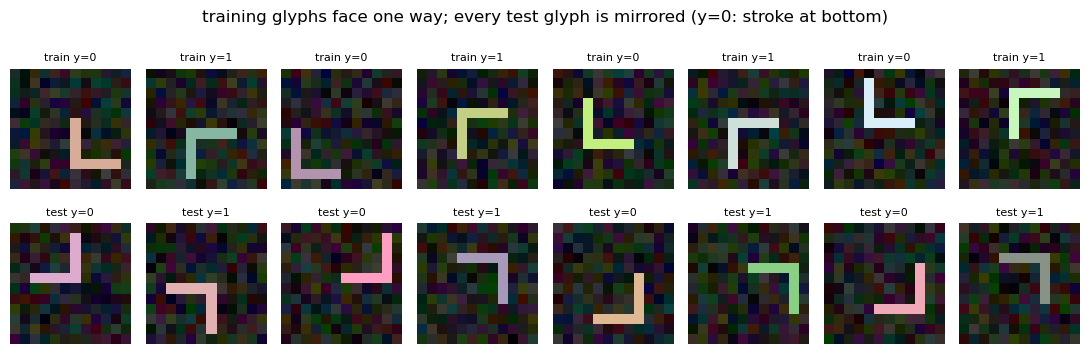

train (32, 3, 12, 12)  test (64, 3, 12, 12)


In [2]:
Xtr_g, ytr_g = canon.make_glyphs(canon.N_TRAIN, canon.DATA_SEED)
Xte_g, yte_g = canon.make_glyphs(canon.N_TEST, canon.TEST_SEED, mirrored=True)
fig, axes = plt.subplots(2, 8, figsize=(11, 3.8))
for k in range(8):
    axes[0, k].imshow(Xtr_g[k].transpose(1, 2, 0)); axes[0, k].set_title(f'train y={ytr_g[k]}', fontsize=8)
    axes[1, k].imshow(Xte_g[k].transpose(1, 2, 0)); axes[1, k].set_title(f'test y={yte_g[k]}', fontsize=8)
for ax in axes.flat: ax.axis('off')
fig.suptitle('training glyphs face one way; every test glyph is mirrored (y=0: stroke at bottom)')
plt.tight_layout(); plt.show()
print('train', Xtr_g.shape, ' test', Xte_g.shape)

## 2. Stride and padding: the two economy dials

Module 03 slid its kernel one pixel at a time and only where it fit. AlexNet
turns both dials. A **stride** $S$ computes only every $S$-th position;
**padding** adds $P_{\text{pad}}$ rings of zeros so windows can center on edge
pixels. One formula covers every case, for convolutions and pooling alike:

$$H_{\text{out}} = \left\lfloor \frac{H + 2P_{\text{pad}} - K}{S} \right\rfloor + 1$$

and the convolution reads the padded input at a strided offset:

$$Y[i,f,u,v] = b_f + \sum_{c,p,q} K[f,c,p,q]\; X[i, c,\, uS{+}p{-}P_{\text{pad}},\, vS{+}q{-}P_{\text{pad}}]$$

(taps that land in the padding read zero). AlexNet's first layer — 11×11
kernels at stride 4 on a 227×227 image — gives $\lfloor(227-11)/4\rfloor+1 = 55$:
a 16× cut in positions at the most expensive layer.

conv1 11x11 /4     227 ->  55
pool 3x3 /2         55 ->  27
conv2 5x5 pad 2     27 ->  27
pool 3x3 /2         27 ->  13
conv3-5 3x3 pad 1   13 ->  13
pool 3x3 /2         13 ->   6


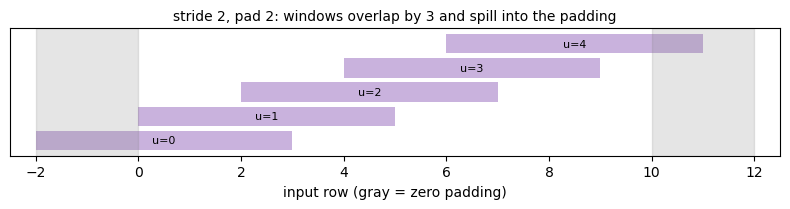

In [3]:
# Every AlexNet stage's output size, from the one formula.
stages = [('conv1 11x11 /4', 227, 11, 4, 0), ('pool 3x3 /2', 55, 3, 2, 0),
          ('conv2 5x5 pad 2', 27, 5, 1, 2), ('pool 3x3 /2', 27, 3, 2, 0),
          ('conv3-5 3x3 pad 1', 13, 3, 1, 1), ('pool 3x3 /2', 13, 3, 2, 0)]
for name, H, K, S, pad in stages:
    print(f'{name:18s} {H:3d} -> {ng.conv_out_size(H, K, S, pad):3d}')

# The toy's conv: 10x10 crop, 5x5 kernel, stride 2, pad 2 -> 5x5. Which input
# rows does each output row read? (the strided windows, padding included)
S, pad, KS, H = 2, 2, 5, 10
fig, ax = plt.subplots(figsize=(8, 2.2))
for u in range(ng.conv_out_size(H, KS, S, pad)):
    lo = u * S - pad
    ax.barh(u, KS, left=lo, color='tab:purple', alpha=0.5)
    ax.text(lo + KS / 2, u, f'u={u}', ha='center', va='center', fontsize=8)
ax.axvspan(-pad, 0, color='gray', alpha=0.2); ax.axvspan(H, H + pad, color='gray', alpha=0.2)
ax.set_xlim(-pad - 0.5, H + pad + 0.5); ax.set_xlabel('input row (gray = zero padding)')
ax.set_yticks([]); ax.set_title('stride 2, pad 2: windows overlap by 3 and spill into the padding', fontsize=10)
plt.tight_layout(); plt.show()

In [4]:
# The vectorized Conv2D (im2col with strided slices + np.pad) must equal the
# naive definition, and its hand-written backward must equal finite differences.
rng = np.random.default_rng(0)
conv = ng.Conv2D(3, 4, 5, 5, stride=2, pad=2)
conv.K[:] = rng.standard_normal(conv.K.shape); conv.b[:] = rng.standard_normal(4)
X = rng.standard_normal((2, 3, 10, 10))
Y = conv.forward(X)
print('output shape', Y.shape, ' max|fast - naive| =',
      f'{np.abs(Y - canon.naive_conv2d_forward(X, conv.K, conv.b, 2, 2)).max():.1e}')
dY = rng.standard_normal(Y.shape)
dX = conv.backward(dY)
for name, analytic, wrt in (('dK', conv.dK, conv.K), ('db', conv.db, conv.b), ('dX', dX, X)):
    err = rel_error(analytic, eval_numerical_gradient_array(lambda _: conv.forward(X), wrt, dY))
    print(f'  {name}: rel_error = {err:.2e}'); assert err < 1e-6

output shape (2, 4, 5, 5)  max|fast - naive| = 7.1e-15
  dK: rel_error = 1.03e-07
  db: rel_error = 1.06e-11


  dX: rel_error = 1.19e-08


## 3. ReLU at scale: the slope that doesn't die

Module 02 met ReLU as one option among three. AlexNet made it *the* choice,
for a reason that only bites at depth and scale: $\tanh'(z) = 1 - \tanh^2(z)$
collapses toward zero for large $|z|$, and backprop multiplies one such factor
per layer. ReLU's slope is exactly 1 wherever the unit is on — gradients pass
through active units unshrunk. The paper's Figure 1: a four-layer CNN on
CIFAR-10 reached 25% training error **six times faster** with ReLUs than with
tanh. We redo that experiment in §9.1 — and it holds a surprise.

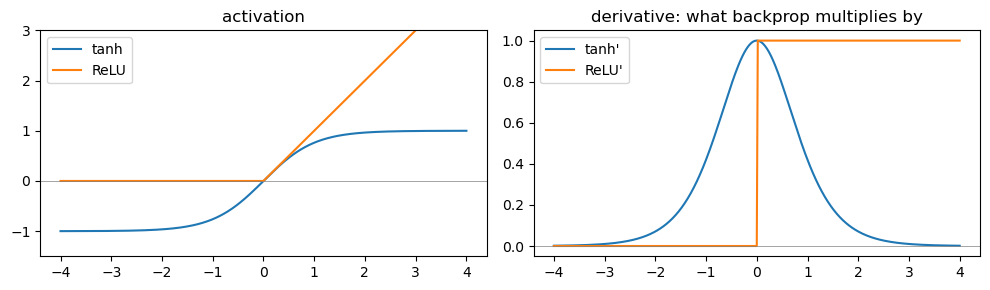

median product of 8 tanh slopes: 1.96e-05
product of 8 ReLU slopes, given the units are on: 1 (exactly)


In [5]:
z = np.linspace(-4, 4, 401)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(z, np.tanh(z), label='tanh'); axes[0].plot(z, np.maximum(z, 0), label='ReLU')
axes[0].set_ylim(-1.5, 3); axes[0].legend(); axes[0].set_title('activation')
axes[1].plot(z, 1 - np.tanh(z) ** 2, label="tanh'"); axes[1].plot(z, (z > 0).astype(float), label="ReLU'")
axes[1].legend(); axes[1].set_title('derivative: what backprop multiplies by')
for ax in axes: ax.axhline(0, c='gray', lw=0.5)
plt.tight_layout(); plt.show()

# Through 8 layers: the product of local slopes at typical pre-activations.
rng = np.random.default_rng(0)
zs = rng.standard_normal((100000, 8)) * 1.5
print('median product of 8 tanh slopes: %.2e' % np.median(np.prod(1 - np.tanh(zs) ** 2, axis=1)))
print('product of 8 ReLU slopes, given the units are on: 1 (exactly)')

## 4. Overlapping pooling

Module 03 pooled non-overlapping 2×2 tiles. AlexNet pools **3×3 windows every
2 pixels** — neighbors share a row or column — and reported slightly lower
error and slightly less overfitting. The new subtlety is in the backward pass: a
cell can be the maximum of *two* windows, and the chain rule says a value used
twice gets both gradients **added**. `MaxPool2D(3, stride=2)` routes and adds.

In [6]:
# How many 3x3/2 windows cover each cell of a 5x5 map (the toy's conv output)?
cover = np.zeros((5, 5), dtype=int)
for u in range(2):
    for v in range(2):
        cover[2 * u:2 * u + 3, 2 * v:2 * v + 3] += 1
print('windows covering each cell:\n', cover)

# A cell that wins two windows collects both gradients.
x = np.zeros((1, 1, 5, 5)); x[0, 0, 2, 2] = 9.0          # center cell beats everything
pool = ng.MaxPool2D(3, 2)
print('pooled:', pool.forward(x)[0, 0].tolist())
print('gradient routed back (dY = 1 everywhere):\n', pool.backward(np.ones((1, 1, 2, 2)))[0, 0])

# Finite differences + the naive definition.
Xp = np.random.default_rng(1).standard_normal((2, 3, 7, 7))
Yp = pool.forward(Xp); dYp = np.random.default_rng(2).standard_normal(Yp.shape)
dXp = pool.backward(dYp)
err = rel_error(dXp, eval_numerical_gradient_array(lambda _: pool.forward(Xp), Xp, dYp))
_, arg = canon.naive_maxpool2d_forward(Xp, 3, 2)
print(f'dX rel_error vs finite differences = {err:.2e};  max|fast - naive| = '
      f'{np.abs(dXp - canon.naive_maxpool2d_backward(dYp, arg, Xp.shape)).max():.1e}')
assert err < 1e-6

windows covering each cell:
 [[1 1 2 1 1]
 [1 1 2 1 1]
 [2 2 4 2 2]
 [1 1 2 1 1]
 [1 1 2 1 1]]
pooled: [[9.0, 9.0], [9.0, 9.0]]
gradient routed back (dY = 1 everywhere):
 [[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 4. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
dX rel_error vs finite differences = 3.28e-12;  max|fast - naive| = 2.2e-16


## 5. Dropout

During training, silence each hidden unit independently with probability
$p$. Every step then trains a different random **thinned** network, and no unit
can count on any particular partner being present — which breaks the brittle
co-adaptations a big network uses to memorize. With $n$ droppable units there
are $2^n$ thinned networks, all sharing one set of weights.

We use **inverted** dropout: survivors are scaled by $1/(1-p)$ during training,

$$m_j = \frac{[\,u_j < 1-p\,]}{1-p}, \quad u_j \sim U[0,1), \qquad y = x \odot m,$$

so $\mathbb{E}[y_j] = x_j$ and evaluation is the plain network. The backward
pass is a gate, like ReLU's but random: $\partial L/\partial x = \partial L/\partial y \odot m$.
(The paper scaled at *test* time instead — outputs times 0.5 — same expectation.)

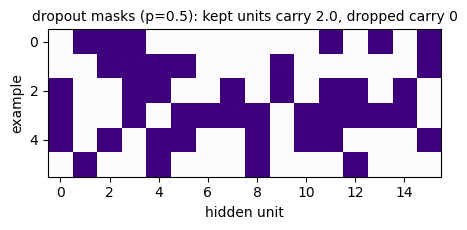

mean of y over 20,000 draws (should be ~1): [1.009 0.995 1.017 1.008 1.003 1.001]
eval mode is identity: True
dropout dX rel_error = 3.28e-12


In [7]:
drop = ng.Dropout(0.5, rng=np.random.default_rng(0))
X = np.ones((6, 16))
Y = drop.forward(X)
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.imshow(drop.mask, cmap='Purples', vmin=0, vmax=2)
ax.set_xlabel('hidden unit'); ax.set_ylabel('example'); ax.set_title('dropout masks (p=0.5): kept units carry 2.0, dropped carry 0', fontsize=10)
plt.tight_layout(); plt.show()

# Expectation is preserved: average many masks.
many = ng.Dropout(0.5, rng=np.random.default_rng(1)).forward(np.ones((20000, 16)))
print('mean of y over 20,000 draws (should be ~1):', np.round(many.mean(axis=0)[:6], 3))

# Evaluation mode is the identity; training-mode backward is dY * mask.
net = ng.Sequential([drop]).eval(); print('eval mode is identity:', np.array_equal(net.forward(X), X))
net.train()
dY = np.random.default_rng(2).standard_normal(Y.shape)
def fwd(_):
    drop.rng = ng.Rng(3)          # hold one mask fixed for the finite differences
    return drop.forward(Xd)
Xd = np.random.default_rng(4).standard_normal((6, 16))
fwd(None); dX = drop.backward(dY)
err = rel_error(dX, eval_numerical_gradient_array(fwd, Xd, dY))
print(f'dropout dX rel_error = {err:.2e}'); assert err < 1e-6

## 6. Data augmentation: free, honest examples

AlexNet trained on random 224×224 crops of 256×256 images, mirrored half the
time, drawn fresh every epoch — $32 \times 32$ offsets $\times$ 2 mirrors, the
paper's "factor of 2048". A shifted or mirrored object is still the same
object, so each variant is a correctly labeled new example. At test time the
network averaged its softmax over ten fixed views (four corners and the
center, each plain and mirrored). The toy does the same with 10×10 crops of
12×12 images; CIFAR-10 uses 24×24 crops of 32×32 — Krizhevsky's own CIFAR recipe.

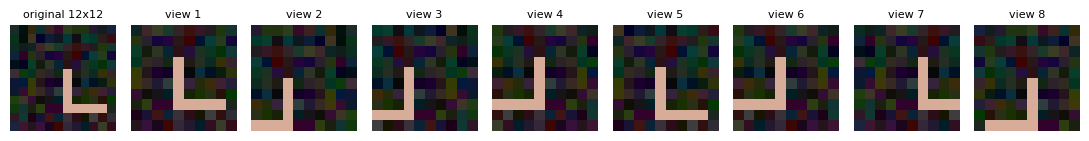

ten_crop views: 10


In [8]:
crops = ng.random_crop_flip(np.repeat(Xtr_g[:1], 8, axis=0), canon.CROP, np.random.default_rng(5))
fig, axes = plt.subplots(1, 9, figsize=(11, 1.6))
axes[0].imshow(Xtr_g[0].transpose(1, 2, 0)); axes[0].set_title('original 12x12', fontsize=8)
for k in range(8):
    axes[k + 1].imshow(crops[k].transpose(1, 2, 0)); axes[k + 1].set_title(f'view {k + 1}', fontsize=8)
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()
print('ten_crop views:', len(ng.ten_crop(Xtr_g[:1], canon.CROP)))

## 7. Toy → trained: who actually bridges the gap?

Four configurations, ten seeds each (vectorized path, so it's quick): no
regularization, crops+flips only, dropout only, both. Same network, same 600
SGD steps with momentum and weight decay. Training accuracy measures
memorization; accuracy on the **mirrored** test glyphs measures what was
learned.

none         train 1.000   mirrored test 0.689 (worst seed 0.53)


crops+flips  train 1.000   mirrored test 0.955 (worst seed 0.89)


dropout      train 1.000   mirrored test 0.675 (worst seed 0.55)


both         train 0.981   mirrored test 0.925 (worst seed 0.89)


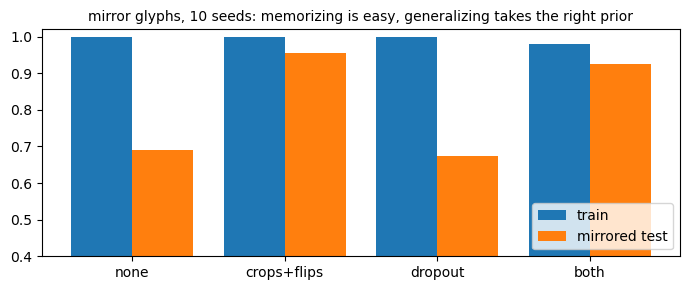

In [9]:
configs = [('none', False, 0.0), ('crops+flips', True, 0.0), ('dropout', False, 0.5), ('both', True, 0.5)]
results = {}
for name, aug, p in configs:
    results[name] = np.array([canon.train_toy_vectorized(augment=aug, drop_p=p, seed=s) for s in range(10)])
    r = results[name]
    print(f'{name:12s} train {r[:, 0].mean():.3f}   mirrored test {r[:, 1].mean():.3f} '
          f'(worst seed {r[:, 1].min():.2f})')

fig, ax = plt.subplots(figsize=(7, 3))
xs = np.arange(len(configs))
ax.bar(xs - 0.2, [results[c[0]][:, 0].mean() for c in configs], 0.4, label='train')
ax.bar(xs + 0.2, [results[c[0]][:, 1].mean() for c in configs], 0.4, label='mirrored test')
ax.set_xticks(xs, [c[0] for c in configs]); ax.set_ylim(0.4, 1.02); ax.legend(loc='lower right')
ax.set_title('mirror glyphs, 10 seeds: memorizing is easy, generalizing takes the right prior', fontsize=10)
plt.tight_layout(); plt.show()
assert results['crops+flips'][:, 1].mean() > results['none'][:, 1].mean() + 0.15

Every configuration memorizes the 32 training glyphs. Only the ones that see
**flips** recognize the mirrored test glyphs: augmentation adds *information*
(an invariance the data didn't show), which no amount of dropout can supply —
dropout only stops the network from leaning on any single unit. Dropout earns
its keep where a network's parameters vastly outnumber its examples, which in
AlexNet means the dense layers (§9). Keep that distinction: regularizers are
not interchangeable.

## 8. Verify against the canonical `alexnet.py` and the C mirror

The scalar `ToyAlexNet` (flat-array loops in the same order as
`lib/c/nanograd/*.c`) is the C↔Python agreement gate: crops, flips, dropout
masks, overlapping pooling and momentum SGD, all from the same LCG streams.
`tests/test_agreement.py` compiles `c/alexnet.c` and asserts the two match.

In [10]:
t0 = time.time()
fp = dict(canon.run_toy())
print(f"{'':9s}{'value':>24s}   ({time.time() - t0:.0f}s of pure-Python loops)")
for k in ('loss', 'acc', 'test_acc', 'wsum', 'k1_0', 'w2_00', 'w3_00', 'b3_0'):
    print(f'{k:9s}{fp[k]:24.15g}')
assert fp['acc'] == 1.0 and fp['test_acc'] >= 0.85
print('OK: toy memorized AND generalizes to mirrored glyphs; c/alexnet.c prints the same digits '
      '(see tests/test_agreement.py)')

                            value   (57s of pure-Python loops)
loss          0.00635638045993687
acc                             1
test_acc                 0.921875
wsum            -15.3091624311928
k1_0           -0.380240442516886
w2_00          -0.062299897018084
w3_00           0.562619132946053
b3_0           -0.189107870557611
OK: toy memorized AND generalizes to mirrored glyphs; c/alexnet.c prints the same digits (see tests/test_agreement.py)


## 9. CIFAR-10: the real thing

60,000 32×32 color photos in ten classes (50,000 train / 10,000 test),
collected by Krizhevsky in 2009 as the small-image stand-in for exactly the
problem ImageNet posed at scale. Our network keeps AlexNet's silhouette —
five convolutions (two followed by overlapping pooling, three stacked, one
more pool), three dense layers with dropout on the two hidden ones, ReLU
throughout — sized for 24×24 crops and a laptop CPU:

    24x24x3 crop -> conv1 5x5 -> pool 3/2 -> conv2 3x3 -> pool 3/2
                 -> conv3 3x3 -> conv4 3x3 -> conv5 3x3 -> pool 3/2
                 -> fc6 -> dropout -> fc7 -> dropout -> fc8 (10)

One honest departure: we train with **Adam** (Module 02), not AlexNet's SGD
with momentum. AlexNet ran ~90 epochs with a hand-dropped learning rate; on a
15-epoch budget a plain 8-layer network *without batch normalization*
(Module 05) learns several times slower under SGD — §9.1's runs use SGD, as
the paper did, and show it. The toy keeps AlexNet's SGD recipe exactly. The
runs are in **float32** — AlexNet's own precision, half the bytes of the
float64 the toy needs for bit-exact agreement (`Sequential.astype`).

Each CIFAR run here takes a long time in NumPy on a laptop CPU, so
`run_cifar(..., cache=True)` saves the trained weights and history under
`data/cifar10/checkpoints/` (gitignored), named by a hash of the full
configuration; an identical call loads them. The notebook says which happened,
and re-evaluates loaded networks from their weights rather than trusting the
recorded numbers. Delete the folder to retrain everything.

train (50000, 3, 32, 32) uint8  test (10000, 3, 32, 32)  channel mean [0.491 0.482 0.447] std [0.247 0.243 0.262]


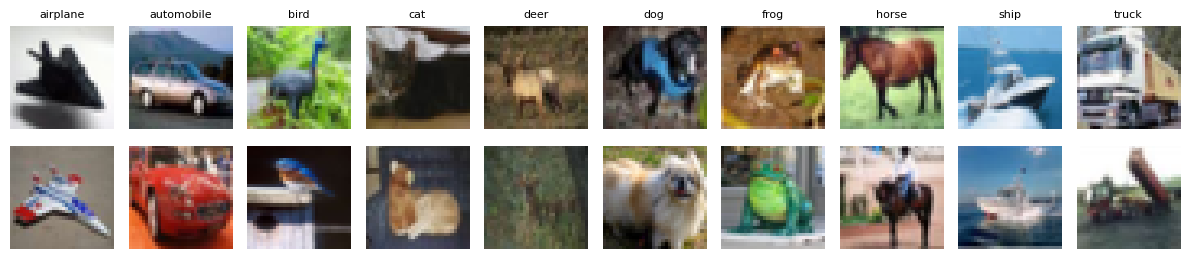

AlexNet-mini: 348,874 parameters


In [11]:
from get_cifar10 import CLASSES
data = canon.load_cifar()
Xtr_c, ytr_c, Xte_c, yte_c, mean, std = data
print('train', Xtr_c.shape, Xtr_c.dtype, ' test', Xte_c.shape, ' channel mean', np.round(mean, 3), 'std', np.round(std, 3))
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for c in range(10):
    idx = np.flatnonzero(ytr_c == c)[:2]
    for r in range(2):
        axes[r, c].imshow(Xtr_c[idx[r]].transpose(1, 2, 0)); axes[r, c].axis('off')
    axes[0, c].set_title(CLASSES[c], fontsize=8)
plt.tight_layout(); plt.show()
net_probe = canon.build_alexnet()
print(f'AlexNet-mini: {canon.n_params(net_probe):,} parameters')

### 9.1 ReLU versus tanh — the paper's Figure 1, redone

Same network, no regularization of any kind (no dropout, no augmentation, no
weight decay), 10,000 training images, SGD with momentum as in the paper,
each activation with the initialization derived for it in Module 02 (He for
ReLU, Xavier for tanh). We track the running training error per epoch and ask
how soon each gets to 50%.

[cifar] loaded checkpoint 73ddf827f77e (10 epochs, test_acc=0.4945)


[cifar] loaded checkpoint 7f47f0cd9e5a (10 epochs, test_acc=0.5371)


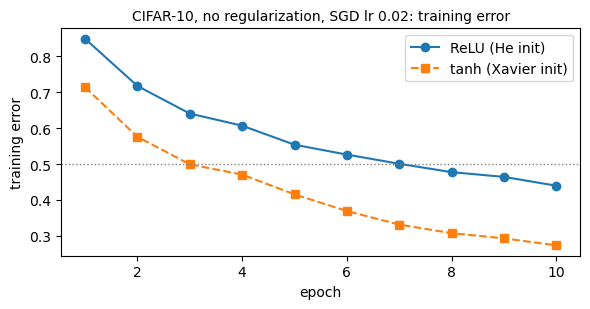

epochs to 50% training error: ReLU 8, tanh 3


In [12]:
SUB = 10000
fig1 = dict(epochs=10, lr_drops=(), train_n=SUB, augment=False, dropout=0.0,
            optimizer='sgd', lr=0.02, weight_decay=0.0, data=data, cache=True, verbose=True)
_, _, hist_relu = canon.run_cifar(activation='relu', **fig1)
_, _, hist_tanh = canon.run_cifar(activation='tanh', **fig1)
fig, ax = plt.subplots(figsize=(6, 3.2))
ep = np.arange(1, len(hist_relu) + 1)
ax.plot(ep, [h['train_err'] for h in hist_relu], 'o-', label='ReLU (He init)')
ax.plot(ep, [h['train_err'] for h in hist_tanh], 's--', label='tanh (Xavier init)')
LEVEL = 0.5
ax.axhline(LEVEL, c='gray', lw=1, ls=':'); ax.set_xlabel('epoch'); ax.set_ylabel('training error')
ax.legend(); ax.set_title('CIFAR-10, no regularization, SGD lr 0.02: training error', fontsize=10)
plt.tight_layout(); plt.show()
er = canon.epochs_to([h['train_err'] for h in hist_relu], LEVEL)
et = canon.epochs_to([h['train_err'] for h in hist_tanh], LEVEL)
print(f'epochs to {LEVEL:.0%} training error: ReLU {er}, tanh {et}')

**The figure does not reproduce.** On this network tanh trains *faster*. Is
that just a learning rate that suits tanh better? The paper picked each
network's rate separately "to make training as fast as possible", so do the
same: a short sweep, five epochs each.

In [13]:
sweep = dict(epochs=5, lr_drops=(), train_n=SUB, augment=False, dropout=0.0, optimizer='sgd',
             weight_decay=0.0, data=data, cache=True, verbose=True)
err5 = {('relu', 0.02): hist_relu[4]['train_err'], ('tanh', 0.02): hist_tanh[4]['train_err']}
for act, lr in [('relu', 0.005), ('relu', 0.01), ('tanh', 0.05)]:
    _, _, h = canon.run_cifar(activation=act, lr=lr, **sweep)
    err5[(act, lr)] = h[-1]['train_err']
print('training error after 5 epochs:')
for (act, lr), e in sorted(err5.items()):
    print(f'  {act:5s} lr={lr:<6} {e:.3f}')
best_relu = min(e for (a, _), e in err5.items() if a == 'relu')
best_tanh = min(e for (a, _), e in err5.items() if a == 'tanh')
print(f'best ReLU {best_relu:.3f}  vs  best tanh {best_tanh:.3f}')
assert er is not None and et is not None and et < er and best_tanh < best_relu

[cifar] loaded checkpoint 8793698acfec (5 epochs, test_acc=0.4286)


[cifar] loaded checkpoint bce061f5cc90 (5 epochs, test_acc=0.4402)


[cifar] loaded checkpoint 93dc75bf225d (5 epochs, test_acc=0.4769)
training error after 5 epochs:
  relu  lr=0.005  0.515
  relu  lr=0.01   0.517
  relu  lr=0.02   0.554
  tanh  lr=0.02   0.416
  tanh  lr=0.05   0.458
best ReLU 0.515  vs  best tanh 0.416


Tuning doesn't change the ordering. We can't rerun 2012's exact experiment,
but the setups differ in ways that plausibly matter: the paper's network had
four layers (ours has eight, with overlapping pooling and dropout-free dense
layers), its weights were drawn at hand-picked fixed scales rather than from a
fan-in rule, and its learning rates were tuned per network over a much longer
run. The paper itself cautions that "the magnitude of the effect demonstrated
here varies with network architecture". Here, with each activation given the
initialization derived for it, tanh is simply not handicapped at this depth.

ReLU won the decade anyway, for reasons this experiment doesn't probe: it is a
comparison instead of an exponential (cheap on 2012 GPUs), and its gradient is
not attenuated by the activations at all, which matters more the deeper a
network gets — where this book goes next. The honest takeaway: a famous
result is a measurement of a setup, and the setup is part of the result.

### 9.2 The regularizers, one at a time

Four networks on the same 10,000-image subset — none, dropout only,
crops+flips only, both — with the clean training accuracy (evaluation mode,
center crops) tracked next to test accuracy. The gap between them is
memorization.

[cifar] loaded checkpoint 9af0591ad60c (30 epochs, test_acc=0.5664)
none         clean train 1.000   test 0.566   gap +0.434


[cifar] loaded checkpoint 00241f40d933 (30 epochs, test_acc=0.5718)
dropout      clean train 0.989   test 0.572   gap +0.417


[cifar] loaded checkpoint 4897ad55e751 (30 epochs, test_acc=0.6630)
crops+flips  clean train 0.747   test 0.663   gap +0.084


[cifar] loaded checkpoint 4f1684324733 (30 epochs, test_acc=0.6277)
both         clean train 0.684   test 0.628   gap +0.056


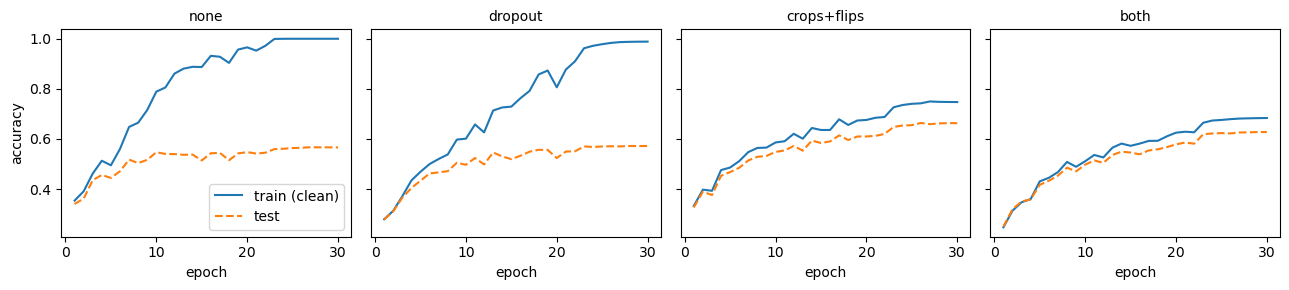

after 10 epochs, unregularized:  SGD+momentum train error 0.44, test 0.494  |  Adam train error 0.28, test 0.547


In [14]:
ablation = {}
for name, aug, p in [('none', False, 0.0), ('dropout', False, 0.5), ('crops+flips', True, 0.0), ('both', True, 0.5)]:
    _, acc, hist = canon.run_cifar(epochs=30, lr_drops=(22, 27), train_n=SUB, augment=aug,
                                   dropout=p, track_train=True, data=data, cache=True, verbose=True)
    ablation[name] = hist
    print(f"{name:12s} clean train {hist[-1]['train_acc']:.3f}   test {acc:.3f}   gap {hist[-1]['train_acc'] - acc:+.3f}")
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, (name, hist) in zip(axes, ablation.items()):
    ep = np.arange(1, len(hist) + 1)
    ax.plot(ep, [h['train_acc'] for h in hist], label='train (clean)')
    ax.plot(ep, [h['test_acc'] for h in hist], '--', label='test')
    ax.set_title(name, fontsize=10); ax.set_xlabel('epoch')
axes[0].set_ylabel('accuracy'); axes[0].legend()
plt.tight_layout(); plt.show()
gap = {k: v[-1]['train_acc'] - v[-1]['test_acc'] for k, v in ablation.items()}
assert gap['both'] < gap['none'] and ablation['both'][-1]['test_acc'] > ablation['none'][-1]['test_acc']

# Why these runs use Adam: the same unregularized ReLU network on the same data,
# after 10 epochs, under AlexNet's SGD (Figure 1's run) and under Adam ('none').
sgd10, adam10 = hist_relu[9], ablation['none'][9]
print(f"after 10 epochs, unregularized:  SGD+momentum train error {sgd10['train_err']:.2f}, "
      f"test {sgd10['test_acc']:.3f}  |  Adam train error {adam10['train_err']:.2f}, test {adam10['test_acc']:.3f}")
assert adam10['train_err'] < sgd10['train_err']

The toy's lesson, at scale. Unregularized, the network memorizes all 10,000
images and stops improving on new ones; dropout *alone* barely changes that.
Crops and flips are the big lever — they add information — lifting test
accuracy by about ten points and collapsing the memorization gap. Adding
dropout on top shrinks the gap a little further but *costs* test accuracy
here: restraint is paid for in capacity and convergence time (the paper notes
dropout "roughly doubles the number of iterations required to converge"),
and in this network the price isn't worth it — with a 2×2 final feature map
only 38% of its parameters live in the dense layers, versus AlexNet's 96%.
The dropout runs also needed the long schedule: at 12 epochs both were still
behind the unregularized network on test accuracy. The canonical run
below keeps AlexNet's full recipe; the dropout-free comparison at full scale
is left as an exercise.

### 9.3 The full run (target ≥ 70%)

All 50,000 training images, crops + flips + dropout, the canonical
configuration of `run_cifar()`.

[cifar] loaded checkpoint 9c6e027d97c2 (15 epochs, test_acc=0.7233)
  epoch  0  train_loss=1.9599  test_acc=0.4175
  epoch  1  train_loss=1.5713  test_acc=0.5047
  epoch  2  train_loss=1.4302  test_acc=0.5731
  epoch  3  train_loss=1.3246  test_acc=0.6008
  epoch  4  train_loss=1.2311  test_acc=0.6208
  epoch  5  train_loss=1.1824  test_acc=0.6460
  epoch  6  train_loss=1.1378  test_acc=0.6619
  epoch  7  train_loss=1.0879  test_acc=0.6702
  epoch  8  train_loss=1.0537  test_acc=0.6842
  epoch  9  train_loss=1.0372  test_acc=0.6788
  epoch 10  train_loss=0.9275  test_acc=0.7145
  epoch 11  train_loss=0.9037  test_acc=0.7175
  epoch 12  train_loss=0.8851  test_acc=0.7254
  epoch 13  train_loss=0.8718  test_acc=0.7244
  epoch 14  train_loss=0.8695  test_acc=0.7233



CIFAR-10 test accuracy (center crop) = 0.7233   (target >= 0.70)


with AlexNet's ten-crop averaging      = 0.7553


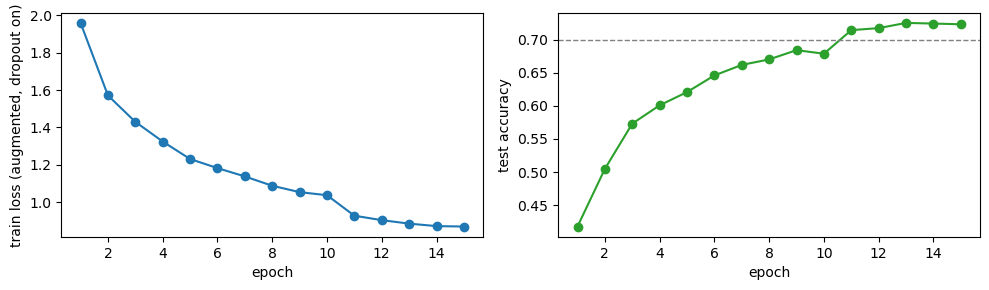

In [15]:
net, _, hist = canon.run_cifar(data=data, cache=True, verbose=True)
for h in hist:
    print(f"  epoch {h['epoch']:2d}  train_loss={h['train_loss']:.4f}  test_acc={h['test_acc']:.4f}")
acc = canon.evaluate(net, Xte_c, yte_c, mean, std)     # from the weights, not the record
print(f'\nCIFAR-10 test accuracy (center crop) = {acc:.4f}   (target >= 0.70)')
assert acc >= 0.70 and abs(acc - hist[-1]['test_acc']) < 1e-9
acc10 = canon.evaluate(net, Xte_c, yte_c, mean, std, views='ten')
print(f'with AlexNet\'s ten-crop averaging      = {acc10:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
ep = np.arange(1, len(hist) + 1)
axes[0].plot(ep, [h['train_loss'] for h in hist], 'o-'); axes[0].set_xlabel('epoch'); axes[0].set_ylabel('train loss (augmented, dropout on)')
axes[1].plot(ep, [h['test_acc'] for h in hist], 'o-', c='tab:green'); axes[1].axhline(0.70, ls='--', c='gray', lw=1)
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('test accuracy')
plt.tight_layout(); plt.show()

### Looking inside: the first layer

AlexNet's Figure 3 — 96 crisp edge and color-blob filters — is the most
reproduced image of the network. Plot ours and they look like colored noise.
Nothing is broken: fifteen epochs on 50,000 small images move the first
layer's weights only about a third of the way from their random start (the
deeper layers move much further), so the random initialization still dominates
the picture. Subtract it — plot what training *changed* — and the structure
appears: smooth color blobs and light-to-dark gradients, with neighboring
kernel taps strongly correlated where the raw weights are not. AlexNet's
filters got their crispness from ninety epochs over 1.2 million images.

layer  0 Conv2D  moved 37% from its init
layer  3 Conv2D  moved 65% from its init
layer  6 Conv2D  moved 96% from its init
layer  8 Conv2D  moved 115% from its init
layer 10 Conv2D  moved 101% from its init
layer 14 Linear  moved 55% from its init
layer 17 Linear  moved 70% from its init
layer 20 Linear  moved 71% from its init
neighbouring-tap correlation: trained -0.03, learned change +0.36


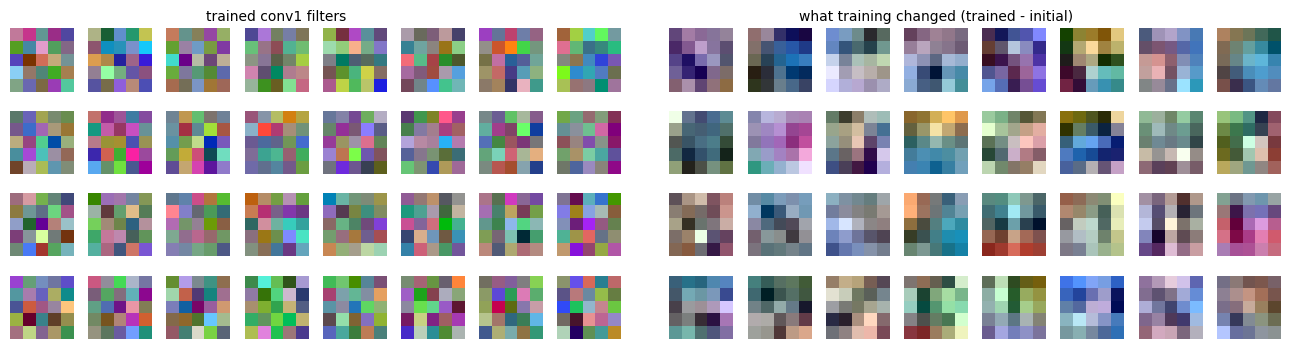

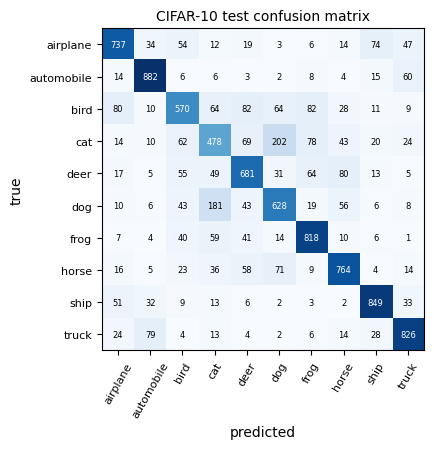

per-class accuracy: {'airplane': 0.737, 'automobile': 0.882, 'bird': 0.57, 'cat': 0.478, 'deer': 0.681, 'dog': 0.628, 'frog': 0.818, 'horse': 0.764, 'ship': 0.849, 'truck': 0.826}


In [16]:
# What conv1 learned: each 5x5x3 filter as a small color image (mid-gray = 0).
# Compare the trained kernels with the same network at initialization.
init = canon.build_alexnet()                      # canonical seed: the exact starting weights
K1, K0 = net.layers[0].K.astype(np.float64), init.layers[0].K.astype(np.float64)
for i, (l, l0) in enumerate(zip(net.layers, init.layers)):
    if isinstance(l, (ng.Conv2D, ng.Linear)):
        p, p0 = (l.K, l0.K) if isinstance(l, ng.Conv2D) else (l.W, l0.W)
        print(f'layer {i:2d} {type(l).__name__:7s} moved {np.linalg.norm(p - p0) / np.linalg.norm(p0):.0%} from its init')

def neighbour_corr(K):
    T = K.transpose(0, 2, 3, 1)
    return np.corrcoef(T[:, :, :-1].ravel(), T[:, :, 1:].ravel())[0, 1]
print(f'neighbouring-tap correlation: trained {neighbour_corr(K1):+.2f}, '
      f'learned change {neighbour_corr(K1 - K0):+.2f}')

fig, axes = plt.subplots(4, 17, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1] * 8 + [0.3] + [1] * 8})
for r in range(4):
    axes[r, 8].axis('off')
    for c in range(8):
        k = r * 8 + c
        axes[r, c].imshow(canon.filter_images(K1)[k], interpolation='nearest')
        axes[r, c + 9].imshow(canon.filter_images(K1 - K0)[k], interpolation='nearest')
for a in axes.flat: a.axis('off')
axes[0, 3].set_title('trained conv1 filters', fontsize=10)
axes[0, 12].set_title('what training changed (trained - initial)', fontsize=10)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 8, figsize=(8, 4.2))
for k, a in enumerate(axes.flat):
    a.imshow(canon.filter_images(K1 - K0)[k], interpolation='nearest'); a.axis('off')
fig.suptitle('conv1 of our CIFAR-10 AlexNet: what training changed', fontsize=11)
plt.tight_layout()
fig.savefig(os.path.join(REPO, 'site', 'public', 'media', '04-alexnet-filters.png'), dpi=110, bbox_inches='tight')
plt.close(fig)

# Confusion matrix: which classes does it mix up?
net.eval()
preds = np.concatenate([net.forward(canon.standardize(np.ascontiguousarray(ng.center_crop(Xte_c[s:s + 500], 24)), mean, std)).argmax(1)
                        for s in range(0, 10000, 500)])
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (yte_c, preds), 1)
fig, ax = plt.subplots(figsize=(5.5, 4.6))
ax.imshow(cm, cmap='Blues'); ax.set_xticks(range(10), CLASSES, rotation=60, fontsize=8); ax.set_yticks(range(10), CLASSES, fontsize=8)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=6, color='white' if cm[i, j] > 400 else 'black')
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title('CIFAR-10 test confusion matrix', fontsize=10)
plt.tight_layout(); plt.show()
per_class = cm.diagonal() / cm.sum(axis=1)
print('per-class accuracy:', {c: round(float(a), 3) for c, a in zip(CLASSES, per_class)})

The paper's other famous figure (Figure 4) took the 4096-number activation of
the last hidden layer as an image's *description* and showed that images with
nearby descriptions look alike to people — even when their pixels don't. The
same test on our fc7 (256 numbers):

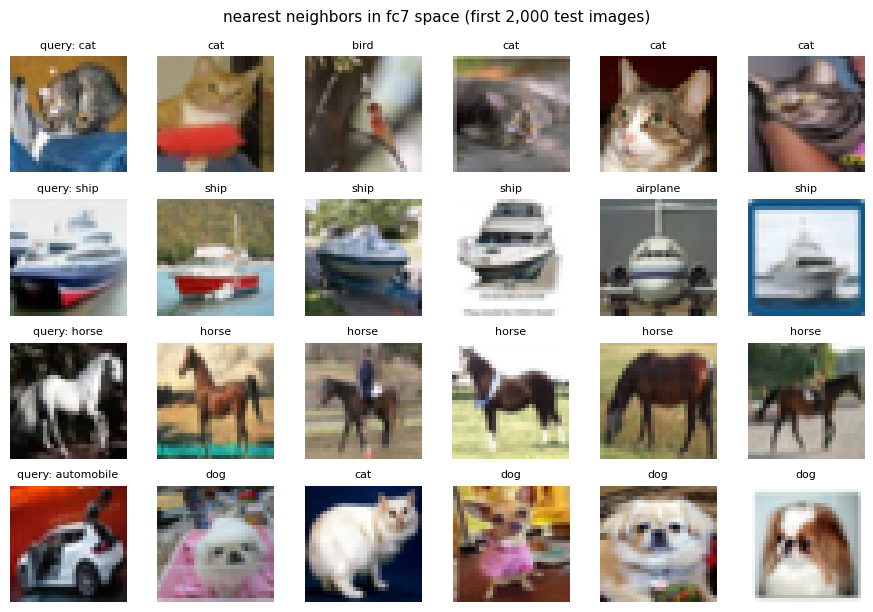

In [17]:
def fc7_features(net, X):
    net.eval()
    feats = []
    for s in range(0, X.shape[0], 500):
        a = canon.standardize(np.ascontiguousarray(ng.center_crop(X[s:s + 500], 24)), mean, std)
        for layer in net.layers[:-1]:          # everything except the classifier
            a = layer.forward(a)
        feats.append(a)
    return np.concatenate(feats)

F = fc7_features(net, Xte_c[:2000])
F = F / (np.linalg.norm(F, axis=1, keepdims=True) + 1e-8)
queries = [int(np.argmax(yte_c[:2000] == c)) for c in (3, 8, 7, 1)]   # a cat, ship, horse, car
fig, axes = plt.subplots(len(queries), 6, figsize=(9, 6.2))
for r, q in enumerate(queries):
    nn = np.argsort(-(F @ F[q]))[1:6]
    for c, i in enumerate([q, *nn]):
        axes[r, c].imshow(Xte_c[i].transpose(1, 2, 0)); axes[r, c].axis('off')
        axes[r, c].set_title(('query: ' if c == 0 else '') + CLASSES[yte_c[i]], fontsize=8)
fig.suptitle('nearest neighbors in fc7 space (first 2,000 test images)', fontsize=11)
plt.tight_layout(); plt.show()

## 10. The historical corner: what AlexNet actually was

The paper's network was this module's mechanisms at full size — and a few
choices history kept, and a few it didn't:

- **Two GPUs.** 60 M parameters and the training activations did not fit in one
  GTX 580's 3 GB, so the network was split down the middle: half the kernels
  on each GPU, talking only at conv3 and the dense layers. (In the paper's
  Figure 3, the GPU-1 half of conv1 learned largely color-agnostic edges and
  the GPU-2 half color blobs — every run.) The split survives as *grouped
  convolution*.
- **Local response normalization** after conv1 and conv2 — "brightness
  normalization" across neighboring channels, credited with 1.2–1.4% of
  error. VGG (2014) found it bought nothing; batch normalization (Module 05)
  replaced it. Its backward pass is still a good chain-rule workout.
- **PCA color augmentation**: add random multiples of the RGB principal
  components to every pixel — illumination changes are not class changes.
- **Init and schedule**: weights $\mathcal{N}(0, 0.01^2)$, biases set to 1 in
  some layers (to start ReLUs in their active region), learning rate 0.01
  divided by 10 three times by hand, ~90 epochs over 1.2 M images: five to
  six days. The 15.3% winning entry averaged seven networks, two of them
  pre-trained on the larger ImageNet Fall-2011 release; one network alone
  scored 18.2% on validation.

In [18]:
# Where AlexNet's parameters and arithmetic live (computed from the paper's shapes).
layers = [('conv1', 96, 11 * 11 * 3, 55 * 55), ('conv2', 256, 5 * 5 * 48, 27 * 27),
          ('conv3', 384, 3 * 3 * 256, 13 * 13), ('conv4', 384, 3 * 3 * 192, 13 * 13),
          ('conv5', 256, 3 * 3 * 192, 13 * 13), ('fc6', 4096, 6 * 6 * 256, 1),
          ('fc7', 4096, 4096, 1), ('fc8', 1000, 4096, 1)]
params = {n: o * f + o for n, o, f, _ in layers}
macs = {n: o * f * pos for n, o, f, pos in layers}
tp, tm = sum(params.values()), sum(macs.values())
print(f"{'layer':6s}{'params':>13s}{'share':>8s}{'mult-adds':>14s}{'share':>8s}")
for n in params:
    print(f'{n:6s}{params[n]:13,}{100 * params[n] / tp:7.1f}%{macs[n]:14,}{100 * macs[n] / tm:7.1f}%')
print(f"{'total':6s}{tp:13,}{'':8s}{tm:14,}")

layer        params   share     mult-adds   share
conv1        34,944    0.1%   105,415,200   14.6%
conv2       307,456    0.5%   223,948,800   30.9%
conv3       885,120    1.5%   149,520,384   20.6%
conv4       663,936    1.1%   112,140,288   15.5%
conv5       442,624    0.7%    74,760,192   10.3%
fc6      37,752,832   61.9%    37,748,736    5.2%
fc7      16,781,312   27.5%    16,777,216    2.3%
fc8       4,097,000    6.7%     4,096,000    0.6%
total    60,965,224           724,406,816


96% of the parameters sit in three dense layers; 92% of the arithmetic in five
convolutions. So dropout went where the parameters were (fc6, fc7) and the
GPUs went where the arithmetic was. Now LRN: gradient-checked, then ablated on
the 10,000-image subset for 12 epochs (crops + flips + dropout in both arms).

In [19]:
lrn = ng.LocalResponseNorm(5, 0.1, 0.75, 2.0)    # alpha raised so the coupling term is visible
Xl = np.random.default_rng(3).standard_normal((2, 7, 3, 3)) * 2
Yl = lrn.forward(Xl); dYl = np.random.default_rng(4).standard_normal(Yl.shape)
err = rel_error(lrn.backward(dYl), eval_numerical_gradient_array(lambda _: lrn.forward(Xl), Xl, dYl))
print(f'LRN dX rel_error = {err:.2e};  max|fast - naive| = {np.abs(Yl - canon.naive_lrn_forward(Xl, 5, 0.1, 0.75, 2.0)).max():.1e}')
assert err < 1e-6

lrn_cfg = dict(epochs=12, lr_drops=(8, 11), train_n=SUB, track_train=True, data=data, cache=True, verbose=True)
_, acc_lrn, _ = canon.run_cifar(lrn=True, **lrn_cfg)
_, acc_nolrn, _ = canon.run_cifar(lrn=False, **lrn_cfg)     # same budget, no LRN
print(f'test accuracy with LRN {acc_lrn:.4f}  vs without {acc_nolrn:.4f}  (difference {acc_lrn - acc_nolrn:+.4f})')

LRN dX rel_error = 3.08e-10;  max|fast - naive| = 2.2e-16


[cifar] loaded checkpoint 26925a2dd94b (12 epochs, test_acc=0.5373)


[cifar] loaded checkpoint 7549cc1bb5ac (12 epochs, test_acc=0.5143)
test accuracy with LRN 0.5373  vs without 0.5143  (difference +0.0230)


At this small scale LRN *helps* — the opposite of VGG's ImageNet finding. One
seed on a 12-epoch, 10,000-image budget is a hint, not a verdict, but it is a
reminder that "obsolete" usually means *superseded*, not *useless*: LRN was
reaching for something real (keeping activation scales in check through the
layers), and batch normalization (Module 05) does that job directly.

AlexNet's other forgotten trick, PCA color augmentation: shift every pixel
along the principal components of the training set's RGB values, because a
photo under warmer light shows the same object.

RGB eigenvalues: [0.0032 0.0141 0.1694] 
eigenvectors (columns):
 [[ 0.418 -0.719 -0.555]
 [-0.816 -0.028 -0.578]
 [ 0.4    0.694 -0.598]]


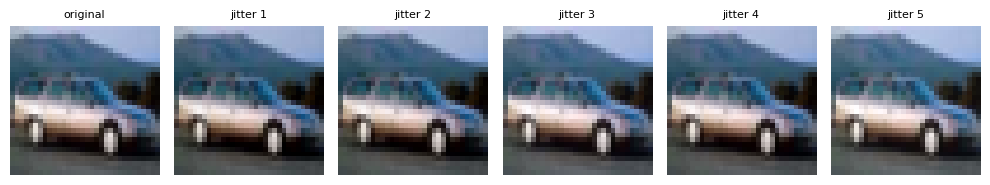

In [20]:
# PCA color augmentation (AlexNet Sec. 4.1): eigenvectors of the RGB covariance over training pixels.
pix = Xtr_c[:2000].transpose(0, 2, 3, 1).reshape(-1, 3).astype(np.float64) / 255.0
evals, evecs = np.linalg.eigh(np.cov(pix, rowvar=False))
print('RGB eigenvalues:', np.round(evals, 4), '\neigenvectors (columns):\n', np.round(evecs, 3))
img = Xtr_c[int(np.argmax(ytr_c == 1))].transpose(1, 2, 0) / 255.0
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 6, figsize=(10, 1.9))
axes[0].imshow(img); axes[0].set_title('original', fontsize=8)
for k in range(1, 6):
    alpha = rng.normal(0, 0.1 * 3, 3)          # 3x the paper's 0.1, so the shift is visible
    shift = evecs @ (alpha * evals)            # [p1 p2 p3][a1*l1, a2*l2, a3*l3]^T, added to every pixel
    axes[k].imshow(np.clip(img + shift, 0, 1)); axes[k].set_title(f'jitter {k}', fontsize=8)
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## 11. Export for the animation

The Manim scene draws the filters, sample photos and curves from exactly
these runs.

In [21]:
canon.export_assets(net, hist_relu, hist_tanh, ablation, data, level=LEVEL)

[export] wrote C:\Users\shaia\development\deep-learning-from-scratch\topics\04-alexnet\anim\alexnet_assets.json


## 12. Framework mirrors: PyTorch, TensorFlow, Keras

The mechanisms were built from scratch above. This closing section shows the
same ideas idiomatically in each framework and **validates** ours against
them — PyTorch strictly (same ops, same numbers, gradient for gradient),
TensorFlow and Keras at the result level.

### 12.1 PyTorch — our layers *are* `F.conv2d(stride, padding)`, `F.max_pool2d(3, 2)`, dropout, `F.local_response_norm`

In [22]:
import torch
import torch.nn.functional as F
rng = np.random.default_rng(10)

# (a) strided + padded convolution, forward and all three gradients.
conv = ng.Conv2D(3, 4, 5, 5, stride=2, pad=2)
conv.K[:] = rng.standard_normal(conv.K.shape); conv.b[:] = rng.standard_normal(4)
Xc = rng.standard_normal((2, 3, 10, 10)); Y_ours = conv.forward(Xc)
dYc = rng.standard_normal(Y_ours.shape); dX_ours = conv.backward(dYc)
Xt = torch.tensor(Xc, requires_grad=True); Kt = torch.tensor(conv.K, requires_grad=True); bt = torch.tensor(conv.b, requires_grad=True)
Yt = F.conv2d(Xt, Kt, bt, stride=2, padding=2); Yt.backward(torch.tensor(dYc))
for name, ours, t in [('Y', Y_ours, Yt.detach()), ('dK', conv.dK, Kt.grad), ('db', conv.db, bt.grad), ('dX', dX_ours, Xt.grad)]:
    err = rel_error(ours, t.numpy()); print(f'(a) conv s2 p2 {name:2s} rel_error = {err:.2e}'); assert err < 1e-12

# (b) overlapping max-pool 3/2.
pool = ng.MaxPool2D(3, 2)
Xp = rng.standard_normal((2, 3, 7, 7)); P_ours = pool.forward(Xp)
dYp = rng.standard_normal(P_ours.shape); dXp_ours = pool.backward(dYp)
Xpt = torch.tensor(Xp, requires_grad=True); Pt = F.max_pool2d(Xpt, 3, 2); Pt.backward(torch.tensor(dYp))
err = max(rel_error(P_ours, Pt.detach().numpy()), rel_error(dXp_ours, Xpt.grad.numpy()))
print(f'(b) maxpool 3/2 fwd+dX rel_error = {err:.2e}'); assert err < 1e-12

# (c) dropout: torch draws its own mask, so compare the semantics, not the bits:
# inverted scaling (kept = x/(1-p)), identity in eval, and dX = dY * mask.
xt = torch.ones(10000, 8, requires_grad=True)
yt = F.dropout(xt, p=0.5, training=True); yt.backward(torch.ones_like(yt))
vals = sorted(set(np.round(yt.detach().numpy().ravel(), 6).tolist()))
print(f'(c) torch dropout values {vals}, mean {yt.mean().item():.3f}; grad == mask: '
      f'{torch.equal(xt.grad, yt.detach())}; eval identity: {torch.equal(F.dropout(xt, 0.5, training=False), xt)}')
assert vals == [0.0, 2.0] and torch.equal(xt.grad, yt.detach())

# (d) LRN: torch divides alpha by n, so pass alpha*n to get the paper's formula.
lrn = ng.LocalResponseNorm(5, 1e-4, 0.75, 2.0)
Xl = rng.standard_normal((2, 7, 3, 3)) * 30; Yl = lrn.forward(Xl); dYl = rng.standard_normal(Yl.shape); dXl = lrn.backward(dYl)
Xlt = torch.tensor(Xl, requires_grad=True); Ylt = F.local_response_norm(Xlt, size=5, alpha=1e-4 * 5, beta=0.75, k=2.0)
Ylt.backward(torch.tensor(dYl))
err = max(rel_error(Yl, Ylt.detach().numpy()), rel_error(dXl, Xlt.grad.numpy()))
print(f'(d) LRN fwd+dX rel_error = {err:.2e}  (torch alpha = paper alpha x 5)'); assert err < 1e-12

# (e) the whole toy AlexNet: every parameter gradient vs autograd, with our
# dropout mask injected into the torch graph.
vnet = canon.build_toy_alexnet(drop_rng=ng.Rng(canon.DROP_SEED))
Xb = ng.center_crop(Xtr_g, canon.CROP); ll = ng.SoftmaxCrossEntropy()
ll.forward(vnet.forward(Xb), ytr_g); vnet.backward(ll.backward())
mask = torch.tensor(vnet.layers[6].mask)
conv_l, fc1, fc2 = vnet.layers[0], vnet.layers[4], vnet.layers[7]
T = {n: torch.tensor(a, requires_grad=True) for n, a in
     [('K1', conv_l.K), ('b1', conv_l.b), ('W2', fc1.W), ('b2', fc1.b), ('W3', fc2.W), ('b3', fc2.b)]}
h = F.max_pool2d(F.relu(F.conv2d(torch.tensor(np.ascontiguousarray(Xb)), T['K1'], T['b1'], stride=2, padding=2)), 3, 2)
h = F.relu(h.flatten(1) @ T['W2'] + T['b2']) * mask
loss = F.cross_entropy(h @ T['W3'] + T['b3'], torch.tensor(ytr_g)); loss.backward()
for n, ours in zip(T, vnet.grads()):
    err = rel_error(ours, T[n].grad.numpy()); print(f'(e) d{n:2s} rel_error = {err:.2e}'); assert err < 1e-10
print('PyTorch agrees: same strided conv, same overlapping pool, same dropout, same LRN, same gradients.')

(a) conv s2 p2 Y  rel_error = 1.00e-14
(a) conv s2 p2 dK rel_error = 1.95e-13
(a) conv s2 p2 db rel_error = 3.42e-15
(a) conv s2 p2 dX rel_error = 2.14e-15
(b) maxpool 3/2 fwd+dX rel_error = 0.00e+00
(c) torch dropout values [0.0, 2.0], mean 0.997; grad == mask: True; eval identity: True
(d) LRN fwd+dX rel_error = 1.45e-15  (torch alpha = paper alpha x 5)
(e) dK1 rel_error = 2.37e-14
(e) db1 rel_error = 4.82e-16
(e) dW2 rel_error = 3.90e-15
(e) db2 rel_error = 1.77e-16
(e) dW3 rel_error = 1.96e-16
(e) db3 rel_error = 1.50e-16
PyTorch agrees: same strided conv, same overlapping pool, same dropout, same LRN, same gradients.


### 12.2 TensorFlow — the same AlexNet-mini with a `GradientTape`

NHWC layout, `tf.image` crops and flips inside the input pipeline, Adam with
the learning rate cut tenfold near the end, dropout via `training=True` — the
canonical NumPy configuration, expressed in TensorFlow.

In [23]:
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
import tensorflow as tf
tf.random.set_seed(0)

def to_nhwc(X):
    # Channels-last first, so the per-channel (3,) mean/std broadcast over the last axis.
    X = X.transpose(0, 2, 3, 1).astype('float32') / 255.0
    return (X - mean.astype('float32')) / std.astype('float32')

Xtr_tf, Xte_tf = to_nhwc(Xtr_c), to_nhwc(Xte_c)
lyr = tf.keras.layers
he = tf.keras.initializers.HeNormal
tf_layers = [lyr.Conv2D(32, 5, padding='same', activation='relu', kernel_initializer=he(0)), lyr.MaxPool2D(3, 2),
             lyr.Conv2D(64, 3, padding='same', activation='relu', kernel_initializer=he(1)), lyr.MaxPool2D(3, 2),
             lyr.Conv2D(96, 3, padding='same', activation='relu', kernel_initializer=he(2)),
             lyr.Conv2D(96, 3, padding='same', activation='relu', kernel_initializer=he(3)),
             lyr.Conv2D(64, 3, padding='same', activation='relu', kernel_initializer=he(4)), lyr.MaxPool2D(3, 2),
             lyr.Flatten(), lyr.Dense(256, activation='relu', kernel_initializer=he(5)), lyr.Dropout(0.5),
             lyr.Dense(256, activation='relu', kernel_initializer=he(6)), lyr.Dropout(0.5), lyr.Dense(10)]

def forward_tf(x, training):
    for l in tf_layers:
        x = l(x, training=training) if isinstance(l, lyr.Dropout) else l(x)
    return x

_ = forward_tf(Xte_tf[:1, 4:28, 4:28], False)
tvars = [v for l in tf_layers for v in l.trainable_variables]
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
opt_tf = tf.keras.optimizers.Adam(learning_rate=1e-3)

def augment(x, y):
    return tf.image.random_flip_left_right(tf.image.random_crop(x, (24, 24, 3))), y

@tf.function
def train_step(xb, yb):
    with tf.GradientTape() as tape:
        loss = loss_fn(yb, forward_tf(xb, True))
    opt_tf.apply_gradients(zip(tape.gradient(loss, tvars), tvars))
    return loss

ds = (tf.data.Dataset.from_tensor_slices((Xtr_tf, ytr_c)).shuffle(50000, seed=0)
      .map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(128).prefetch(2))
for epoch in range(10):
    opt_tf.learning_rate.assign(1e-3 if epoch < 8 else 1e-4)
    for xb, yb in ds:
        train_step(xb, yb)
logits = np.concatenate([forward_tf(Xte_tf[s:s + 1000, 4:28, 4:28], False).numpy() for s in range(0, 10000, 1000)])
tf_acc = float((logits.argmax(1) == yte_c).mean())
print(f'TensorFlow AlexNet-mini test accuracy = {tf_acc:.4f}  (10 epochs)'); assert tf_acc >= 0.65

TensorFlow AlexNet-mini test accuracy = 0.7082  (10 epochs)


### 12.3 Keras — the mirror and dropout as layers, crops in the pipeline

`RandomFlip` and `Dropout` are layers that switch themselves off at inference —
exactly our `train()`/`eval()`. Crops are the exception: Keras's `RandomCrop`
layer crops a whole batch at one location and, at inference, resizes the
image instead of center-cropping it — not AlexNet's per-image crops — so the
crops go in the `tf.data` pipeline and evaluation uses center crops, as ours
does.

In [24]:
import keras
from keras import layers
keras.utils.set_random_seed(0)
model = keras.Sequential([
    keras.Input((24, 24, 3)),
    layers.RandomFlip('horizontal'),                 # a no-op at inference
    layers.Conv2D(32, 5, padding='same', activation='relu', kernel_initializer='he_normal'), layers.MaxPooling2D(3, 2),
    layers.Conv2D(64, 3, padding='same', activation='relu', kernel_initializer='he_normal'), layers.MaxPooling2D(3, 2),
    layers.Conv2D(96, 3, padding='same', activation='relu', kernel_initializer='he_normal'),
    layers.Conv2D(96, 3, padding='same', activation='relu', kernel_initializer='he_normal'),
    layers.Conv2D(64, 3, padding='same', activation='relu', kernel_initializer='he_normal'), layers.MaxPooling2D(3, 2),
    layers.Flatten(),
    layers.Dense(256, activation='relu', kernel_initializer='he_normal'), layers.Dropout(0.5),
    layers.Dense(256, activation='relu', kernel_initializer='he_normal'), layers.Dropout(0.5),
    layers.Dense(10, activation='softmax'),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cut = keras.callbacks.LearningRateScheduler(lambda e: 1e-3 if e < 8 else 1e-4)
crops = (tf.data.Dataset.from_tensor_slices((Xtr_tf, ytr_c)).shuffle(50000, seed=1)
         .map(lambda x, y: (tf.image.random_crop(x, (24, 24, 3)), y), num_parallel_calls=tf.data.AUTOTUNE)
         .batch(128).prefetch(2))
model.fit(crops, epochs=10, callbacks=[cut], verbose=0)
keras_acc = model.evaluate(Xte_tf[:, 4:28, 4:28], yte_c, verbose=0)[1]     # center crops
print(f'Keras AlexNet-mini test accuracy = {keras_acc:.4f}  (10 epochs)'); assert keras_acc >= 0.65

C:\Users\shaia\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Keras AlexNet-mini test accuracy = 0.6883  (10 epochs)


---

**What we built.** Stride and padding, overlapping pooling, dropout, local
response normalization and crop+flip augmentation joined `nanograd` in C and
Python (agreeing to the last printed digit on the toy), each checked against
its definition and finite differences — and the tiny toy showed the lesson
that matters most: memorizing is easy; generalizing needs either more data or
the right prior, and augmentation manufactures both.

**Next → Module 05 (ResNet):** AlexNet had eight layers. VGG went to nineteen
and got better — and then deeper plain networks got *worse*, even on their
training data. Not overfitting: something about depth itself. The fix was a
single addition.